In [1]:
from langchain_ollama import ChatOllama
from typing import TypedDict


model = ChatOllama(
    model="llama3.2:1b"
)
class Review(TypedDict):## automatic ek system promt generate hunda hai
    summary:str
    sentiment:str



structuredModel=model.with_structured_output(Review)
result=structuredModel.invoke("The hardware is great, but the software feels bloated. There are too many pre-installed apps that I can't remove. Also, the UI looks outdated compared to other brands. Hoping for a software update to fix this.")

print(result)

{'summary': "Hardware and software issues can be frustrating, especially when it comes to the UI and pre-installed apps. A software update might be able to address these concerns. However, the company may not be able to remove all pre-installed apps or update the UI. Some users have reported similar issues, so it's possible that this is a widespread problem.", 'sentiment': 'mixed'}


### annotated

apne llm ko guide kr skde hai jaise isme to simple tha summary sentiments nikalo hm guide kr skde hai llm ko apne attributed ke baare mai

In [15]:
from langchain_ollama import ChatOllama
from typing import TypedDict,Annotated,Optional,List,Literal


model = ChatOllama(
    model="llama3.2:1b"
)
class Review(TypedDict):## automatic ek system promt generate hunda hai
    key_themes:Annotated[List[str],"discuss the key themes of a review in a list"]
    summary:Annotated[str,"A brief summary of review"]
    sentiment:Annotated[Literal['pos','neg'],'Return the sentiment ']
    pros:Annotated[Optional[List[str]],'write down all prons in list']
    cons:Annotated[Optional[List[str]],'write down all cons in list']



structuredModel=model.with_structured_output(Review)
result=structuredModel.invoke(""" I recently upgraded to the Samsung Galaxy S24 Ultra, and I must say, it’s an absolute powerhouse! The Snapdragon 8 Gen 3 processor makes everything lightning fast—whether I’m gaming, multitasking, or editing photos. The 5000mAh battery easily lasts a full day even with heavy use, and the 45W fast charging is a lifesaver.

The S-Pen integration is a great touch for note-taking and quick sketches, though I don't use it often. What really blew me away is the 200MP camera—the night mode is stunning, capturing crisp, vibrant images even in low light. Zooming up to 100x actually works well for distant objects, but anything beyond 30x loses quality.

However, the weight and size make it a bit uncomfortable for one-handed use. Also, Samsung’s One UI still comes with bloatware—why do I need five different Samsung apps for things Google already provides? The $1,300 price tag is also a hard pill to swallow.

Pros:

Insanely powerful processor (great for gaming and productivity)

Stunning 200MP camera with incredible zoom capabilities

Long battery life with fast charging

S-Pen support is unique and useful

Cons:

Bulky and heavy—not great for one-handed use

Bloatware still exists in One UI

Expensive compared to competitors""")

print(result)

{'key_themes': ['processor', 'camera', 'battery', 'charging', 'pencil', 'bloatware', 'price'], 'summary': "The Samsung Galaxy S24 Ultra is a powerhouse with a 8 Gen 3 processor, 5000mAh battery, and 45W fast charging. However, it has some drawbacks, such as a bulky and heavy design, bloatware in One UI, and a pricey $1,300 price tag. It's worth considering for its many features and capabilities, but may not be the best choice for everyone.", 'sentiment': 'neg', 'pros': ['Powerful processor for gaming and productivity', 'Stunning 200MP camera with incredible zoom capabilities', 'Long battery life with fast charging'], 'cons': ['Bulky and heavy', 'Bloatware in One UI', 'Expensive compared to competitors']}


validation ni hai available typeddict vich maan le mainu bs review ta chahida agr oh 3 star haieda di validation ni kr skde typed dict vich is lyi vi we use pydantic

## pydantic

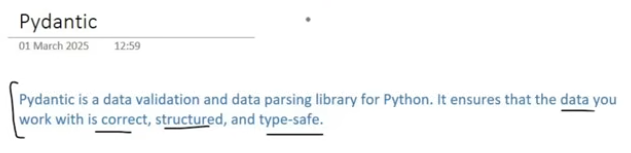

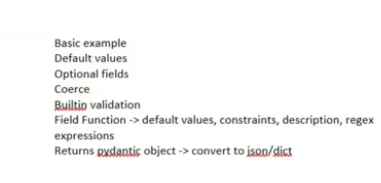

In [16]:
!pip install pydantic

In [ ]:
from pydantic import BaseModel,EmailStr,Field
from typing import Optional
class Student(BaseModel):
    name:str='akshat'
    age:Optional[int]=None
    email:EmailStr
    cgpa:float=Field(gt=0,lt=10,default=5,description='value of cgpa')


new_student={
    'name':'nitish',
    'email':'abc@gmail.com',
    'cgpa':1
}
student=Student(**new_student)
print(student)


name='nitish' age=None email='abc@gmail.com' cgpa=1.0


In [37]:
from langchain_ollama import ChatOllama
from typing import TypedDict,Annotated,Optional,List,Literal
from pydantic import BaseModel,Field

model = ChatOllama(
    model="llama3.2:1b"
)
class Review(BaseModel):## automatic ek system promt generate hunda hai
    key_themes: list[str] = Field(description="Write down all the key themes discussed in the review in a list")
    summary: str = Field(description="A brief summary of the review")
    sentiment: Literal["pos", "neg"] = Field(description="Return sentiment of the review either negative, positive or neutral")
    pros: Optional[list[str]] = Field(default=None, description="Write down all the pros inside a list")
    cons: Optional[list[str]] = Field(default=None, description="Write down all the cons inside a list")
    name: Optional[str] = Field(default=None, description="Write the name of the reviewer")



structuredModel=model.with_structured_output(Review)
result=structuredModel.invoke(""" I recently upgraded to the Samsung Galaxy S24 Ultra, and I must say, it’s an absolute powerhouse! The Snapdragon 8 Gen 3 processor makes everything lightning fast—whether I’m gaming, multitasking, or editing photos. The 5000mAh battery easily lasts a full day even with heavy use, and the 45W fast charging is a lifesaver.

The S-Pen integration is a great touch for note-taking and quick sketches, though I don't use it often. What really blew me away is the 200MP camera—the night mode is stunning, capturing crisp, vibrant images even in low light. Zooming up to 100x actually works well for distant objects, but anything beyond 30x loses quality.

However, the weight and size make it a bit uncomfortable for one-handed use. Also, Samsung’s One UI still comes with bloatware—why do I need five different Samsung apps for things Google already provides? The $1,300 price tag is also a hard pill to swallow.

Pros:

Insanely powerful processor (great for gaming and productivity)

Stunning 200MP camera with incredible zoom capabilities

Long battery life with fast charging

S-Pen support is unique and useful

Cons:

Bulky and heavy—not great for one-handed use

Bloatware still exists in One UI

Expensive compared to competitors""")

print(result)

key_themes=['powerful', 'high-performance'] summary="The Samsung Galaxy S24 Ultra is a high-end smartphone with impressive specs and features. While it's a great device for those who want the latest and greatest, it may not be the best option for everyone. Here are some pros and cons to consider before making a decision." sentiment='neg' pros=None cons=None name=None


# JSON SCHEMA

used when you are using different languages in your project like you are using python for backend and javascript for front end

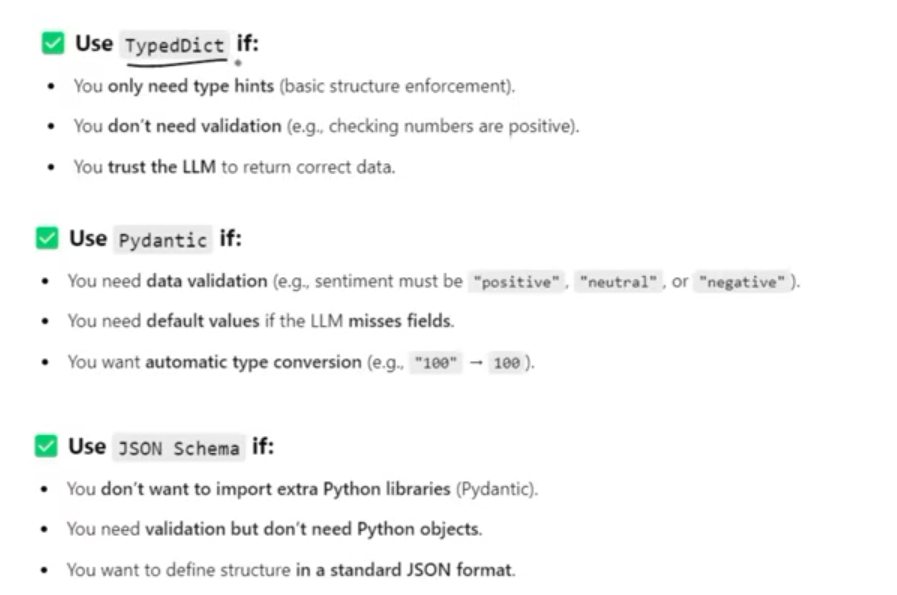

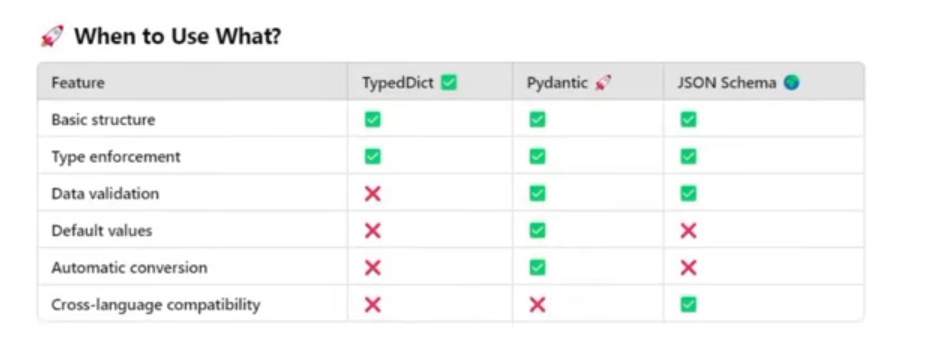